# Phân loại cảm xúc bình luận bằng Naive Bayes (PyTorch)

**Dữ liệu:** `cleaned_data.xlsx` — dùng cột `Clean Text` (đã làm sạch, tách từ) và nhãn `Final Label` (Positive / Neutral / Negative).

**Mô hình:** Multinomial Naive Bayes, tự cài đặt bằng PyTorch (chạy trên GPU nếu có).

**Quy trình:**
1. Đọc dữ liệu → khám phá
2. Chia train / validation / test (70 / 15 / 15)
3. Biến câu thành vector đếm từ (Bag-of-Words)
4. Huấn luyện Naive Bayes: tính **prior** $P(c)$ và **likelihood** $P(w \mid c)$
5. Chọn siêu tham số $\alpha$ trên tập validation
6. Đánh giá trên tập test bằng Accuracy, Precision, Recall, F1, Confusion matrix

## 1. Import thư viện

In [1]:
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)

SEED = 42
np.random.seed(SEED); torch.manual_seed(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device, '|', torch.cuda.get_device_name(0) if device.type == 'cuda' else 'CPU')

Device: cuda | NVIDIA A100-PCIE-40GB


## 2. Đọc dữ liệu & khám phá

In [2]:
df = pd.read_excel('cleaned_data.xlsx')
df = df[['Clean Text', 'Final Label']].dropna()
df['Clean Text'] = df['Clean Text'].astype(str).str.strip()
df = df[df['Clean Text'] != ''].reset_index(drop=True)
print('Số mẫu:', len(df))
df.head()

Số mẫu: 3314


,Clean Text,Final Label
0,anh già rồi anh vẫn đỉnh rất,Positive
1,anh_trai đóng phản_diện chuẩn luôn_luôn,Positive
2,mình anh_em trong phim mà_lại,Neutral
3,anh ngoan bên thiên đường_máu làm trùm rồi qua...,Neutral
4,chén bà bầu bà bếp ngồi ôm gối thôi,Neutral


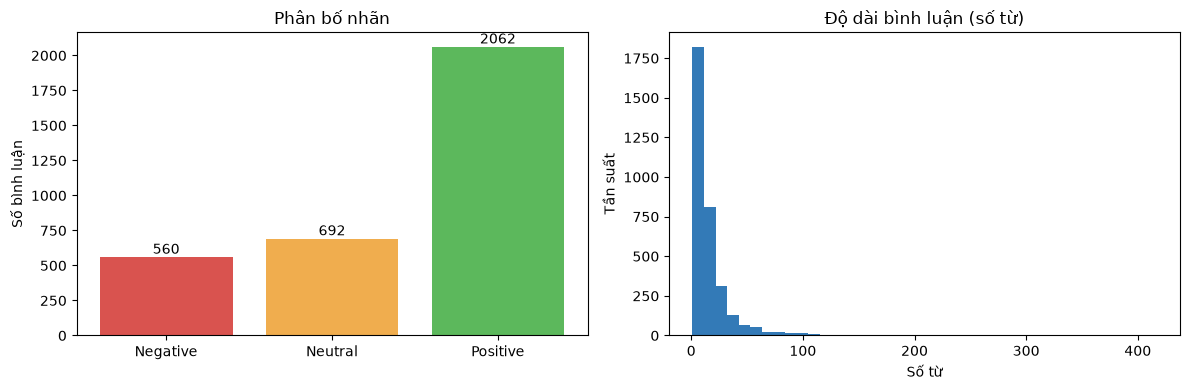

Final Label
Negative     560
Neutral      692
Positive    2062
Name: count, dtype: int64


In [3]:
CLASSES = ['Negative', 'Neutral', 'Positive']
counts = df['Final Label'].value_counts().reindex(CLASSES)
lengths = df['Clean Text'].str.split().str.len()

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
bars = ax[0].bar(CLASSES, counts.values, color=['#d9534f', '#f0ad4e', '#5cb85c'])
ax[0].bar_label(bars)
ax[0].set_title('Phân bố nhãn'); ax[0].set_ylabel('Số bình luận')
ax[1].hist(lengths, bins=40, color='#337ab7')
ax[1].set_title('Độ dài bình luận (số từ)'); ax[1].set_xlabel('Số từ'); ax[1].set_ylabel('Tần suất')
plt.tight_layout(); plt.show()
print(counts)

## 3. Chia train / validation / test (70 / 15 / 15, stratified)

Ta chia dữ liệu thành 3 phần, mỗi phần có một vai trò riêng:

| Tập | Tỉ lệ | Vai trò |
|---|---|---|
| **Train** | 70% | Mô hình **học** từ đây (đếm tần suất từ) |
| **Validation** | 15% | Dùng để **chọn siêu tham số** $\alpha$ |
| **Test** | 15% | Chỉ dùng **một lần cuối** để báo cáo kết quả khách quan |

**Stratified** nghĩa là giữ nguyên tỉ lệ các lớp ở mỗi tập. Ví dụ Positive chiếm khoảng 62% toàn bộ dữ liệu thì cũng chiếm khoảng 62% trong train, val và test:

$$\frac{N_{c}^{\text{train}}}{N^{\text{train}}} \approx \frac{N_{c}^{\text{val}}}{N^{\text{val}}} \approx \frac{N_{c}^{\text{test}}}{N^{\text{test}}} \approx \frac{N_c}{N}$$

In [4]:
label2id = {c: i for i, c in enumerate(CLASSES)}
X = df['Clean Text'].values
y = df['Final Label'].map(label2id).values

X_train, X_tmp, y_train, y_tmp = train_test_split(X, y, test_size=0.30, stratify=y, random_state=SEED)
X_val, X_test, y_val, y_test = train_test_split(X_tmp, y_tmp, test_size=0.50, stratify=y_tmp, random_state=SEED)
print(f'Train: {len(X_train)} | Val: {len(X_val)} | Test: {len(X_test)}')

Train: 2319 | Val: 497 | Test: 498


## 4. Vector hóa Bag-of-Words (túi từ)

Máy tính không hiểu chữ, nên ta biến mỗi câu thành **một vector số**. Mỗi chiều của vector ứng với một từ trong từ điển, và giá trị là **số lần từ đó xuất hiện** trong câu:

$$\mathbf{x} = (x_1, x_2, \dots, x_{|V|}), \qquad x_w = \text{số lần từ } w \text{ xuất hiện trong câu}$$

trong đó $|V|$ là kích thước từ điển (vocabulary).

**Ví dụ:** từ điển $V$ = [`phim`, `hay`, `dở`, `quá`]

| Câu | phim | hay | dở | quá |
|---|---|---|---|---|
| "phim hay quá" | 1 | 1 | 0 | 1 |
| "phim dở dở quá" | 1 | 0 | 2 | 1 |

- Ta dùng cả **unigram** (1 từ, vd `hay`) và **bigram** (2 từ liền nhau, vd `phim hay`), nhờ vậy giữ được một chút ngữ cảnh.
- Từ đã được tách sẵn (vd `anh_trai`), nên chỉ cần tách theo khoảng trắng.
- Từ điển **chỉ học từ tập train**, để mô hình không "nhìn trộm" dữ liệu val/test.

In [5]:
vectorizer = CountVectorizer(token_pattern=r'\S+', ngram_range=(1, 2), min_df=1)
Xtr = vectorizer.fit_transform(X_train)
Xva = vectorizer.transform(X_val)
Xte = vectorizer.transform(X_test)
vocab = np.array(vectorizer.get_feature_names_out())
print('Kích thước vocabulary:', len(vocab))

to_tensor = lambda m: torch.tensor(m.toarray(), dtype=torch.float32, device=device)
Xtr_t, Xva_t, Xte_t = to_tensor(Xtr), to_tensor(Xva), to_tensor(Xte)
ytr_t = torch.tensor(y_train, device=device)

Kích thước vocabulary: 29688


## 5. Thuật toán Naive Bayes

### 5.0 Ý tưởng chính: định lý Bayes

Cho một câu $d$, ta muốn biết câu đó thuộc lớp $c$ (Negative / Neutral / Positive) với xác suất bao nhiêu:

$$P(c \mid d) = \frac{P(c)\; P(d \mid c)}{P(d)}$$

| Ký hiệu | Tên gọi | Ý nghĩa dễ hiểu |
|---|---|---|
| $P(c)$ | **Prior** | Trước khi đọc câu, lớp $c$ phổ biến cỡ nào? |
| $P(d \mid c)$ | **Likelihood** | Nếu câu thuộc lớp $c$ thì khả năng viết ra đúng câu này là bao nhiêu? |
| $P(c \mid d)$ | **Posterior** | Sau khi đọc câu, xác suất câu thuộc lớp $c$ |
| $P(d)$ | Evidence | Giống nhau cho mọi lớp nên **bỏ qua** khi so sánh |

**Giả định "ngây thơ" (naive):** các từ trong câu **độc lập** với nhau khi đã biết lớp. Nhờ vậy xác suất của cả câu bằng tích xác suất của từng từ:

$$P(d \mid c) = \prod_{w \in V} P(w \mid c)^{x_w}$$

Từ đó suy ra **công thức phân loại**: chọn lớp có điểm cao nhất.

$$\hat{y} = \arg\max_c \; P(c) \prod_{w} P(w \mid c)^{x_w}$$

Nhân nhiều xác suất nhỏ sẽ ra số cực nhỏ, dễ bị làm tròn về 0. Vì vậy ta lấy **log** để chuyển tích thành tổng:

$$\boxed{\;\hat{y} = \arg\max_c \Big[\log P(c) + \sum_{w} x_w \log P(w \mid c)\Big]\;}$$

Như vậy, **huấn luyện** Naive Bayes chỉ gồm 2 việc: tính $P(c)$ (bước 5.1) và tính $P(w \mid c)$ (bước 5.2).

### 5.1 Tính Prior $P(c)$

Prior là **tỉ lệ số câu thuộc lớp $c$** trong tập train:

$$P(c) = \frac{N_c}{N}$$

- $N_c$: số câu trong train có nhãn $c$
- $N$: tổng số câu trong train

**Ví dụ:** train có 1000 câu, trong đó 620 câu Positive, thì $P(\text{Positive}) = 620 / 1000 = 0.62$.

In [6]:
def compute_log_prior(y, n_classes):
    class_count = torch.bincount(y, minlength=n_classes).float()   # N_c cho từng lớp
    prior = class_count / class_count.sum()                         # P(c) = N_c / N
    return torch.log(prior)

log_prior_demo = compute_log_prior(ytr_t, len(CLASSES))
for c, lp in zip(CLASSES, log_prior_demo):
    print(f'P({c:<8}) = {lp.exp().item():.4f}   ->   log P = {lp.item():.4f}')

P(Negative) = 0.1690   ->   log P = -1.7776
P(Neutral ) = 0.2087   ->   log P = -1.5668
P(Positive) = 0.6223   ->   log P = -0.4744


### 5.2 Tính Likelihood $P(w \mid c)$, có làm trơn Laplace

Likelihood cho biết **từ $w$ xuất hiện thường xuyên đến đâu trong các câu thuộc lớp $c$**:

$$P(w \mid c) = \frac{N_{c,w} + \alpha}{N_c^{\text{từ}} + \alpha\,|V|}$$

| Ký hiệu | Ý nghĩa |
|---|---|
| $N_{c,w}$ | Tổng số lần từ $w$ xuất hiện trong **tất cả** câu thuộc lớp $c$ |
| $N_c^{\text{từ}} = \sum_{w} N_{c,w}$ | Tổng số từ của lớp $c$ |
| $\lvert V \rvert$ | Kích thước từ điển |
| $\alpha$ | Hệ số **làm trơn Laplace** (smoothing) |

**Vì sao cần $\alpha$?** Nếu từ `dở` chưa từng xuất hiện trong lớp Positive thì $N_{c,w}=0$, kéo theo $P(\text{dở} \mid \text{Positive}) = 0$. Khi đó cả tích bằng 0 (hay $\log 0 = -\infty$), và một từ duy nhất "giết chết" cả lớp. Cộng thêm $\alpha$ giúp mọi xác suất luôn lớn hơn 0.

**Ví dụ:** trong lớp Positive, từ `hay` xuất hiện 50 lần, lớp có tổng 2000 từ, từ điển có 10000 từ, chọn $\alpha = 1$:

$$P(\text{hay} \mid \text{Positive}) = \frac{50 + 1}{2000 + 1 \times 10000} = \frac{51}{12000} \approx 0.00425$$

**Cài đặt bằng ma trận:** gọi $Y$ là ma trận one-hot của nhãn (kích thước $N \times C$) và $X$ là ma trận đếm từ ($N \times |V|$). Khi đó $Y^\top X$ (kích thước $C \times |V|$) chính là bảng $N_{c,w}$ cho mọi lớp và mọi từ, tính trong một phép nhân trên GPU.

In [7]:
def compute_log_likelihood(X, y, n_classes, alpha):
    one_hot = torch.nn.functional.one_hot(y, n_classes).float()     # Y: (N, C)
    word_count = one_hot.T @ X                                       # N_{c,w}: (C, |V|)
    smoothed = word_count + alpha                                    # N_{c,w} + α
    likelihood = smoothed / smoothed.sum(dim=1, keepdim=True)        # chia cho N_c^từ + α|V|
    return torch.log(likelihood)

log_lik_demo = compute_log_likelihood(Xtr_t, ytr_t, len(CLASSES), alpha=1.0)
print('Kích thước bảng log P(w|c):', tuple(log_lik_demo.shape), '(số lớp x số từ)')
for w in ['hay', 'dở', 'phim']:
    if w in vectorizer.vocabulary_:
        j = vectorizer.vocabulary_[w]
        print(f'{w:>5}: ' + ' | '.join(f'P(w|{c}) = {log_lik_demo[i, j].exp().item():.5f}'
                                       for i, c in enumerate(CLASSES)))

Kích thước bảng log P(w|c): (3, 29688) (số lớp x số từ)
  hay: P(w|Negative) = 0.00202 | P(w|Neutral) = 0.00167 | P(w|Positive) = 0.00996
   dở: P(w|Negative) = 0.00039 | P(w|Neutral) = 0.00007 | P(w|Positive) = 0.00012
 phim: P(w|Negative) = 0.00633 | P(w|Neutral) = 0.00373 | P(w|Positive) = 0.01258


### 5.3 Dự đoán

Với mỗi câu mới có vector $\mathbf{x}$, ta tính **điểm** cho từng lớp:

$$\text{score}(c) = \log P(c) + \sum_{w} x_w \log P(w \mid c)$$

Viết dưới dạng ma trận cho cả tập dữ liệu cùng lúc:
$\;\text{Scores} = X \cdot (\log P(w \mid c))^\top + \log P(c)$.

Nhãn dự đoán là lớp có điểm cao nhất: $\hat{y} = \arg\max_c \text{score}(c)$.

Muốn đổi điểm thành **xác suất** (tổng các lớp bằng 1), ta dùng softmax:

$$P(c \mid d) = \frac{e^{\text{score}(c)}}{\sum_{c'} e^{\text{score}(c')}}$$

Trong code, softmax được tính ở dạng log bằng `logsumexp` để tránh tràn số.

**Ví dụ:** câu "phim hay" có $\mathbf{x}$: `phim`=1, `hay`=1

$$\text{score}(\text{Pos}) = \log P(\text{Pos}) + \log P(\text{phim} \mid \text{Pos}) + \log P(\text{hay} \mid \text{Pos})$$

Tính tương tự cho Neg và Neu. Lớp nào có score lớn nhất thì câu được gán vào lớp đó.

Dưới đây ta gói 3 bước 5.1, 5.2, 5.3 vào một class `MultinomialNB`:

In [8]:
class MultinomialNB:
    def __init__(self, alpha=1.0):
        self.alpha = alpha

    def fit(self, X, y, n_classes):
        self.log_prior = compute_log_prior(y, n_classes)                              # bước 5.1
        self.log_likelihood = compute_log_likelihood(X, y, n_classes, self.alpha)     # bước 5.2
        return self

    def predict_log_proba(self, X):                                                   # bước 5.3
        scores = X @ self.log_likelihood.T + self.log_prior                           # score(c): (N, C)
        return scores - torch.logsumexp(scores, dim=1, keepdim=True)                  # log softmax

    def predict(self, X):
        return self.predict_log_proba(X).argmax(dim=1).cpu().numpy()                  # argmax_c

## 6. Các thước đo đánh giá (metric) & chọn siêu tham số α

### 6.1 Metric

Với mỗi lớp $c$, ta đếm:
- **TP** (True Positive): thật là $c$, đoán là $c$ (đoán đúng)
- **FP** (False Positive): thật **không** phải $c$ nhưng đoán là $c$ (báo nhầm)
- **FN** (False Negative): thật là $c$ nhưng đoán sang lớp khác (bỏ sót)

| Metric | Công thức | Ý nghĩa dễ hiểu |
|---|---|---|
| **Accuracy** | $\dfrac{\text{số câu đoán đúng}}{\text{tổng số câu}}$ | Tỉ lệ đoán đúng nói chung |
| **Precision** | $\dfrac{TP}{TP + FP}$ | Trong những câu mô hình **bảo** là $c$, bao nhiêu % đúng là $c$? |
| **Recall** | $\dfrac{TP}{TP + FN}$ | Trong những câu **thật sự** là $c$, mô hình tìm ra được bao nhiêu %? |
| **F1** | $\dfrac{2 \cdot P \cdot R}{P + R}$ | Trung bình điều hòa của Precision và Recall, cân bằng cả hai |

**Macro** = lấy trung bình cộng metric của 3 lớp, mỗi lớp có trọng số như nhau:

$$\text{Macro-F1} = \frac{1}{C} \sum_{c=1}^{C} F1_c$$

**Vì sao dùng Macro-F1 để chọn mô hình?** Dữ liệu lệch (Positive khoảng 62%). Một mô hình "lười" đoán mọi câu là Positive vẫn đạt Accuracy khoảng 62%, nhưng F1 của lớp Negative và Neutral bằng 0, nên Macro-F1 rất thấp. Macro-F1 phạt kiểu mô hình này, còn Accuracy thì không.

### 6.2 Chọn α

- $\alpha$ **nhỏ**: mô hình tin gần như tuyệt đối vào số đếm trên train, dễ **overfit** (học thuộc).
- $\alpha$ **lớn**: mọi từ có xác suất gần như bằng nhau, mô hình bị "mờ" và đoán gần như chỉ dựa vào prior, dễ **underfit**.

Ta thử nhiều giá trị $\alpha$, huấn luyện trên **train**, đo trên **validation**, rồi chọn:

$$\alpha^* = \arg\max_{\alpha} \; \text{Macro-F1}_{\text{val}}(\alpha)$$

In [9]:
def evaluate(y_true, y_pred):
    acc = accuracy_score(y_true, y_pred)
    p, r, f1, _ = precision_recall_fscore_support(y_true, y_pred, average='macro', zero_division=0)
    return {'Accuracy': acc, 'Precision': p, 'Recall': r, 'F1': f1}

alphas = [0.01, 0.05, 0.1, 0.2, 0.3, 0.5, 0.75, 1.0, 1.5, 2.0, 3.0, 5.0]
history = []
for a in alphas:
    m = MultinomialNB(alpha=a).fit(Xtr_t, ytr_t, len(CLASSES))
    tr = evaluate(y_train, m.predict(Xtr_t))
    va = evaluate(y_val, m.predict(Xva_t))
    history.append({'alpha': a, 'train_acc': tr['Accuracy'], 'train_f1': tr['F1'],
                    'val_acc': va['Accuracy'], 'val_f1': va['F1']})
hist = pd.DataFrame(history)
best_alpha = hist.loc[hist['val_f1'].idxmax(), 'alpha']
print('α tốt nhất:', best_alpha)
hist.round(4)

α tốt nhất: 0.1


,alpha,train_acc,train_f1,val_acc,val_f1
0,0.01,0.9892,0.9866,0.7143,0.5856
1,0.05,0.9875,0.9846,0.7123,0.5886
2,0.10,0.9866,0.9834,0.7203,0.5960
3,0.20,0.9815,0.9772,0.7103,0.5653
4,0.30,0.9806,0.9761,0.7163,0.5620
5,0.50,0.9733,0.9673,0.7062,0.5272
6,0.75,0.9608,0.9519,0.6881,0.4749
7,1.00,0.9470,0.9347,0.6579,0.3890
8,1.50,0.9073,0.8830,0.6479,0.3475
9,2.00,0.8568,0.8094,0.6419,0.3288


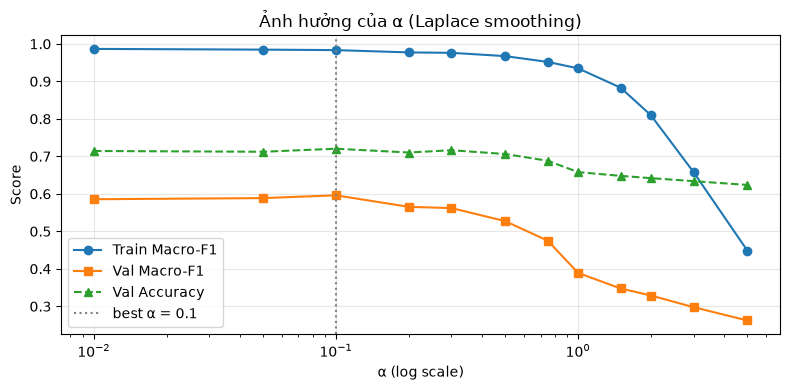

In [10]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(hist['alpha'], hist['train_f1'], 'o-', label='Train Macro-F1')
ax.plot(hist['alpha'], hist['val_f1'], 's-', label='Val Macro-F1')
ax.plot(hist['alpha'], hist['val_acc'], '^--', label='Val Accuracy')
ax.axvline(best_alpha, color='gray', ls=':', label=f'best α = {best_alpha}')
ax.set_xscale('log'); ax.set_xlabel('α (log scale)'); ax.set_ylabel('Score')
ax.set_title('Ảnh hưởng của α (Laplace smoothing)'); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 7. Huấn luyện mô hình cuối & đánh giá trên tập test

Dùng $\alpha^*$ vừa chọn để huấn luyện lại trên train, sau đó đánh giá trên cả 3 tập:
- Train cao hơn nhiều so với Val/Test nghĩa là mô hình có overfit.
- **Test** là con số cuối cùng để báo cáo, vì tập này chưa từng được dùng để học hay chọn tham số.

In [11]:
model = MultinomialNB(alpha=best_alpha).fit(Xtr_t, ytr_t, len(CLASSES))

results = pd.DataFrame({
    'Train': evaluate(y_train, model.predict(Xtr_t)),
    'Validation': evaluate(y_val, model.predict(Xva_t)),
    'Test': evaluate(y_test, model.predict(Xte_t)),
}).T
print('(Precision / Recall / F1 là trung bình macro)')
results.round(4)

(Precision / Recall / F1 là trung bình macro)


,Accuracy,Precision,Recall,F1
Train,0.9866,0.9864,0.9804,0.9834
Validation,0.7203,0.6583,0.5693,0.5960
Test,0.7068,0.6410,0.5607,0.5845


**Báo cáo chi tiết từng lớp** gồm Precision, Recall, F1 (công thức ở mục 6.1) cho mỗi lớp, và `support` là số câu thật sự thuộc lớp đó trong tập test.
- `macro avg`: trung bình cộng 3 lớp
- `weighted avg`: trung bình có trọng số theo support, $\sum_c \frac{\text{support}_c}{N} \cdot F1_c$

In [12]:
y_pred = model.predict(Xte_t)
print(classification_report(y_test, y_pred, target_names=CLASSES, digits=4))

              precision    recall  f1-score   support

    Negative     0.5738    0.4167    0.4828        84
     Neutral     0.6032    0.3654    0.4551       104
    Positive     0.7460    0.9000    0.8158       310

    accuracy                         0.7068       498
   macro avg     0.6410    0.5607    0.5845       498
weighted avg     0.6871    0.7068    0.6843       498



### Confusion matrix (ma trận nhầm lẫn)

Ô ở hàng $i$, cột $j$ là **số câu có nhãn thật $i$ nhưng bị đoán là $j$**:

$$M_{ij} = \#\{\text{câu} : y = i,\ \hat{y} = j\}$$

- **Đường chéo** $M_{ii}$: các câu đoán đúng (chính là $TP$ của lớp $i$). Đường chéo càng đậm thì mô hình càng tốt.
- **Ngoài đường chéo**: các câu đoán nhầm. Nhìn vào đây để biết mô hình hay nhầm lớp nào sang lớp nào.
- Bản **chuẩn hóa theo hàng**: chia mỗi hàng cho tổng hàng, $\dfrac{M_{ii}}{\sum_j M_{ij}} = \text{Recall}_i$.

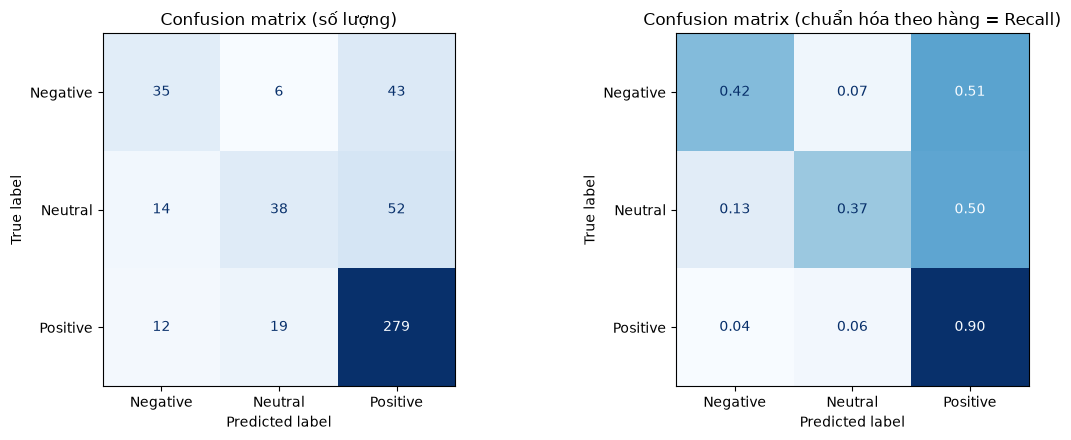

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm, display_labels=CLASSES).plot(ax=ax[0], cmap='Blues', colorbar=False)
ax[0].set_title('Confusion matrix (số lượng)')
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred, normalize='true'), display_labels=CLASSES)\
    .plot(ax=ax[1], cmap='Blues', colorbar=False, values_format='.2f')
ax[1].set_title('Confusion matrix (chuẩn hóa theo hàng = Recall)')
plt.tight_layout(); plt.show()

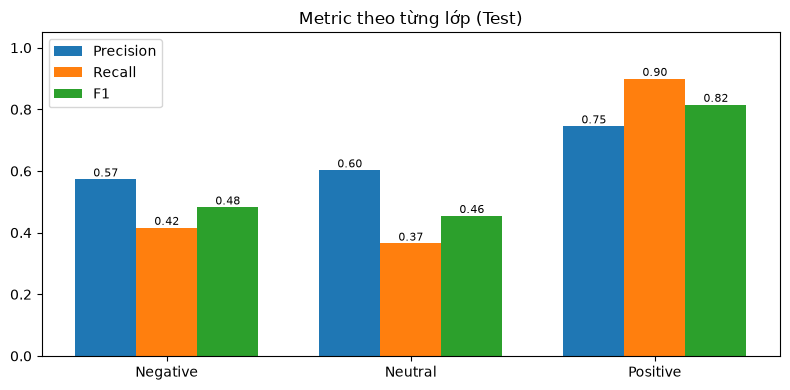

In [14]:
# So sánh metric theo từng lớp trên tập test
p, r, f1, sup = precision_recall_fscore_support(y_test, y_pred, zero_division=0)
x = np.arange(len(CLASSES)); w = 0.25
fig, ax = plt.subplots(figsize=(8, 4))
for i, (vals, name) in enumerate([(p, 'Precision'), (r, 'Recall'), (f1, 'F1')]):
    b = ax.bar(x + (i - 1) * w, vals, w, label=name)
    ax.bar_label(b, fmt='%.2f', fontsize=8)
ax.set_xticks(x); ax.set_xticklabels(CLASSES); ax.set_ylim(0, 1.05)
ax.set_title('Metric theo từng lớp (Test)'); ax.legend()
plt.tight_layout(); plt.show()

## 8. Diễn giải mô hình: các từ đặc trưng nhất của mỗi lớp

Điểm mạnh của Naive Bayes là **dễ giải thích**: ta có thể xem từ nào "kéo" câu về lớp nào.

Với mỗi lớp $c$, điểm đặc trưng của từ $w$ được tính bằng:

$$\text{score}_c(w) = \log P(w \mid c) - \max_{c' \ne c} \log P(w \mid c')$$

- $\text{score}_c(w) > 0$: từ $w$ xuất hiện trong lớp $c$ **nhiều hơn** mọi lớp khác.
- Điểm càng cao thì từ $w$ càng là "dấu hiệu" của lớp $c$. Ví dụ điểm bằng 2 nghĩa là $P(w \mid c)$ lớn gấp khoảng $e^2 \approx 7.4$ lần so với lớp đứng thứ hai.

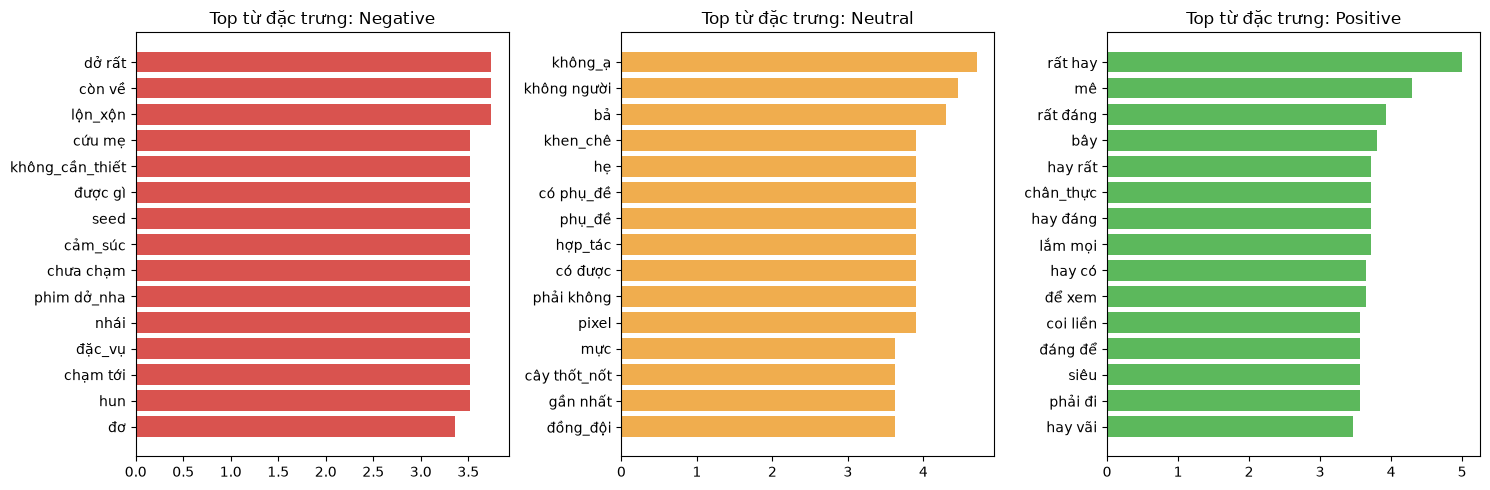

In [15]:
ll = model.log_likelihood.cpu().numpy()
fig, axes = plt.subplots(1, len(CLASSES), figsize=(15, 5))
colors = ['#d9534f', '#f0ad4e', '#5cb85c']
for c, ax in enumerate(axes):
    others = np.delete(ll, c, axis=0).max(axis=0)
    score = ll[c] - others
    top = np.argsort(score)[-15:]
    ax.barh(vocab[top], score[top], color=colors[c])
    ax.set_title(f'Top từ đặc trưng: {CLASSES[c]}')
plt.tight_layout(); plt.show()

## 9. Thử dự đoán vài câu mới

Áp dụng đúng quy trình ở mục 5.3:
1. Vector hóa câu thành $\mathbf{x}$ (dùng từ điển của train)
2. Tính $\text{score}(c) = \log P(c) + \sum_w x_w \log P(w \mid c)$
3. Dùng softmax để ra xác suất $P(c \mid d)$, sau đó chọn lớp lớn nhất

*Lưu ý:* từ nào không có trong từ điển train sẽ bị bỏ qua ($x_w = 0$).

In [16]:
def predict_text(texts):
    Xn = to_tensor(vectorizer.transform(texts))
    proba = model.predict_log_proba(Xn).exp().cpu().numpy()
    for t, pr in zip(texts, proba):
        print(f'{CLASSES[pr.argmax()]:>8}  { {c: round(float(v), 3) for c, v in zip(CLASSES, pr)} }  <- "{t}"')

predict_text(['phim hay quá diễn_viên đóng rất đạt',
              'phim dở tệ nhạt nhẽo',
              'tập sau chiếu lúc nào vậy'])

Positive  {'Negative': 0.0, 'Neutral': 0.0, 'Positive': 1.0}  <- "phim hay quá diễn_viên đóng rất đạt"
Negative  {'Negative': 0.988, 'Neutral': 0.004, 'Positive': 0.009}  <- "phim dở tệ nhạt nhẽo"
Positive  {'Negative': 0.046, 'Neutral': 0.475, 'Positive': 0.479}  <- "tập sau chiếu lúc nào vậy"


Một số mẫu bị phân loại sai trên tập test, dùng để phân tích lỗi:

In [17]:
wrong = pd.DataFrame({'text': X_test, 'true': [CLASSES[i] for i in y_test],
                      'pred': [CLASSES[i] for i in y_pred]})
wrong[wrong.true != wrong.pred].head(10)

,text,true,pred
1,8h35 mới xem bà oi,Neutral,Positive
3,cú nhất đoạn nhỏ bị mang đi oạch,Negative,Neutral
6,ít khi kiểm lắm e ăn_mặc phong_thái chững_chạc...,Neutral,Positive
8,không_ý bà tôi thấy người_ta áp nên tôi cũng l...,Neutral,Positive
13,đạo_diễn toni chắc cũng lấy tí ý_tưởng mùa 1 q...,Neutral,Positive
16,có_lẽ mình quá mong_chờ nên hơi thất_vọng,Negative,Positive
27,có không ta,Neutral,Positive
30,phim hay kết không_chấp_nhận được,Negative,Positive
33,vậy_mà nói lấy câu_chuyện thật để làm phim mé ...,Negative,Positive
34,để tiền xem end game imax cười,Negative,Positive


## 10. Kết luận

- Multinomial Naive Bayes là baseline đơn giản. Huấn luyện chỉ là **đếm tần suất** ($P(c)$ và $P(w \mid c)$) nên cực nhanh và dễ diễn giải.
- Siêu tham số $\alpha$ được chọn bằng tập validation. Kết quả cuối cùng báo cáo trên tập test, là tập chưa từng được dùng khi huấn luyện hay chọn tham số.
- Dữ liệu mất cân bằng (Positive chiếm đa số), nên cần nhìn **Macro-F1** và **Recall từng lớp**, không chỉ nhìn Accuracy.
- **Hạn chế:** giả định "các từ độc lập" khiến mô hình không hiểu ngữ cảnh và phủ định (vd "không hay" vẫn chứa từ `hay`), nên lớp Neutral và Negative dễ bị nhầm sang Positive.